# Phase 3: Promotion Lift and Statistical Testing

**Project:** FMCG Global Demand Planning Capstone
**Input:** `data/fmcg_clean.csv` and `data/abc_xyz_segments.csv`
**Output:** `data/promo_lift_by_series.csv` (one row per store-SKU series)

## Questions
1. Is the raw promo gap seen in Phase 2 (+89% units) a *real* promotion effect, or does it come from *when and where* promotions run?
2. After removing seasonality, is promo lift statistically significant (t-test, with a non-parametric check)?
3. **Does lift differ by channel?** (one-way ANOVA, as in the project roadmap). Also by category, country and ABC class.
4. How does lift change with discount depth (10%, 15%, 20%, 30%)?
5. Is a promotion actually **profitable** once the discount is subtracted?

## Method in one paragraph
Phase 2 showed strong **category-specific seasonality** (Beverages peak in summer, Snacks in Nov-Dec) and a weekend effect. If promotions happen to fall on busy periods, a raw comparison overstates lift. So we (a) estimate seasonal and weekday factors from **non-promo** days, (b) divide units by those factors to get *adjusted units*, and (c) compare each series' promo days to its **own** non-promo days. Each series gives one lift number, and we test those numbers across series. Stock-out rows are excluded because stock-outs understate true demand.

## 1. Setup and load data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats as st
from statsmodels.stats.multicomp import pairwise_tukeyhsd

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams["figure.figsize"] = (9, 4)

df = pd.read_csv("../data/fmcg_clean.csv", parse_dates=["date"])
df["series_id"] = df["store_id"] + "_" + df["sku_id"]

# Gross profit per row = net sales minus the cost of the units sold.
df["gross_profit"] = df["net_sales"] - df["units_sold"] * df["purchase_cost"]

print("Rows:", f"{len(df):,}", "| Series:", df["series_id"].nunique())
print("Promo share of rows:", round(df["promo_flag"].mean() * 100, 1), "%")

Rows: 1,100,000 | Series: 1005
Promo share of rows: 8.0 %


In [3]:
# Exclude stock-out rows: sales on those days are capped by missing stock,
# so they understate demand and would bias the lift estimate.
dfa = df[df["stock_out_flag"] == 0].copy()
print("Rows kept after removing stock-outs:", f"{len(dfa):,}", f"(removed {len(df) - len(dfa):,})")

Rows kept after removing stock-outs: 1,066,886 (removed 33,114)


## 2. Are promotions spread evenly? (confounding check)
If promotions cluster in certain months, weekdays or categories, the raw promo vs non-promo gap mixes the promotion effect with those patterns. We check what share of rows is on promotion in each group. If the shares are about equal everywhere, confounding is a smaller worry.

In [4]:
for col in ["month", "weekday", "category", "channel", "country"]:
    share = dfa.groupby(col)["promo_flag"].mean() * 100
    print(f"\nPromo share of rows (%) by {col}:")
    print(share.round(1).to_string())

per_series = dfa.groupby("series_id")["promo_flag"].mean() * 100
print("\nPromo share per series (%), distribution across series:")
print(per_series.describe().round(1))


Promo share of rows (%) by month:
month
1    8.500
2    8.000
3    8.000
4    8.600
5    8.100
6    7.400
7    8.300
8    8.100
9    7.900
10   7.800
11   7.500
12   8.000

Promo share of rows (%) by weekday:
weekday
0   8.000
1   8.100
2   7.900
3   8.100
4   8.000
5   8.100
6   7.900

Promo share of rows (%) by category:
category
Beverages       9.200
Dairy           6.000
Home Care       6.200
Personal Care   7.700
Snacks          9.800

Promo share of rows (%) by channel:
channel
Convenience   9.000
E-commerce    8.100
Hypermarket   8.000
Supermarket   7.800

Promo share of rows (%) by country:
country
Austria       7.500
France        8.200
Germany       8.100
Italy         7.900
Netherlands   9.000
Poland        8.500
Spain         7.800

Promo share per series (%), distribution across series:
count   1,005.000
mean        8.000
std         9.800
min         0.000
25%         0.000
50%         0.000
75%        19.900
max        20.600
Name: promo_flag, dtype: float64


## 3. Build seasonally adjusted units
Using **non-promo** rows only (so promotions do not contaminate the baseline):
- **Category x month index:** average units in that category and month, divided by the category's overall average.
- **Weekday index:** average units on that weekday, divided by the overall average.

Adjusted units = units / (category-month index x weekday index). Adjusted units remove predictable seasonal and weekday effects, so promo and non-promo days become comparable.

In [5]:
base = dfa[dfa["promo_flag"] == 0]

cat_mean = base.groupby("category")["units_sold"].mean()
cm = base.groupby(["category", "month"])["units_sold"].mean()
cm_idx = (cm / cm.index.get_level_values("category").map(cat_mean).values).rename("cm_idx")

wd_idx = base.groupby("weekday")["units_sold"].mean() / base["units_sold"].mean()

dfa = dfa.merge(cm_idx.reset_index(), on=["category", "month"], how="left")
dfa["wd_idx"] = dfa["weekday"].map(wd_idx)
dfa["factor"] = dfa["cm_idx"] * dfa["wd_idx"]

dfa["units_adj"] = dfa["units_sold"] / dfa["factor"]
dfa["profit_adj"] = dfa["gross_profit"] / dfa["factor"]

print("Weekday index:\n", wd_idx.round(3).to_string())
print("\nAny missing factors?", dfa["factor"].isna().sum())

Weekday index:
 weekday
0   0.945
1   0.947
2   0.944
3   0.944
4   0.947
5   1.134
6   1.137

Any missing factors? 0


## 4. Series-level promo lift
For every store-SKU series we compute the average (adjusted) units on promo days and on non-promo days, then:

**lift = promo average / non-promo average - 1**

We also compute the raw (unadjusted) lift to show how much the adjustment changes the answer.

In [6]:
g = (dfa.groupby(["series_id", "promo_flag"])
        .agg(units_adj=("units_adj", "mean"),
             units_raw=("units_sold", "mean"),
             profit_adj=("profit_adj", "mean"),
             n=("units_sold", "size"))
        .unstack("promo_flag"))
g.columns = [f"{a}_{b}" for a, b in g.columns]

lifts = g.dropna(subset=["units_adj_0", "units_adj_1"]).copy()
print("Series with both promo and non-promo days:", len(lifts), "of", dfa["series_id"].nunique())
print("Fewest promo days in any series:", int(lifts["n_1"].min()),
      "| fewest non-promo days:", int(lifts["n_0"].min()))

lifts["lift_raw"] = lifts["units_raw_1"] / lifts["units_raw_0"] - 1
lifts["lift_adj"] = lifts["units_adj_1"] / lifts["units_adj_0"] - 1
lifts["lift_pct"] = lifts["lift_adj"] * 100

print("\nMean lift, raw (%):     ", round(lifts["lift_raw"].mean() * 100, 1))
print("Mean lift, adjusted (%):", round(lifts["lift_adj"].mean() * 100, 1))
print(lifts["lift_pct"].describe().round(1))

Series with both promo and non-promo days: 403 of 1005
Fewest promo days in any series: 203 | fewest non-promo days: 827

Mean lift, raw (%):      86.6
Mean lift, adjusted (%): 87.2
count   403.000
mean     87.200
std       4.600
min      73.200
25%      84.100
50%      86.800
75%      90.300
max      99.600
Name: lift_pct, dtype: float64


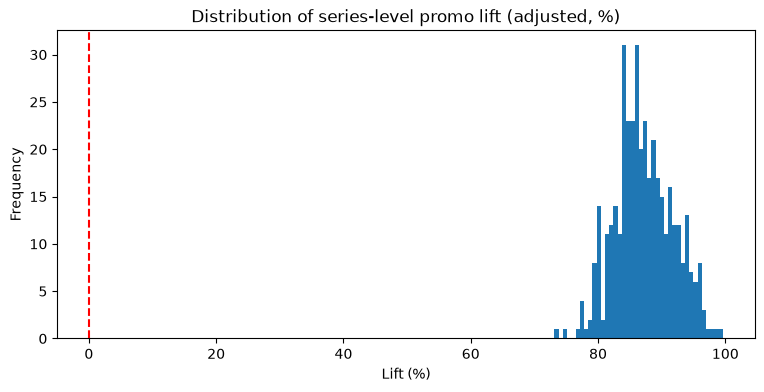

In [7]:
lifts["lift_pct"].plot(kind="hist", bins=40, title="Distribution of series-level promo lift (adjusted, %)")
plt.axvline(0, color="red", linestyle="--")
plt.xlabel("Lift (%)")
plt.show()

## 5. Is the lift statistically significant?
Three complementary tests across series:
- **One-sample t-test:** is the mean lift different from 0?
- **Paired t-test:** are promo-day averages higher than non-promo averages *for the same series*?
- **Wilcoxon signed-rank test:** the same question without assuming a normal distribution (a robustness check).

We also report a **95% confidence interval** and **Cohen's d** (effect size: roughly 0.2 small, 0.5 medium, 0.8 large). With ~1,000 series, even a tiny effect gives a tiny p-value, so the *size* of the lift matters more than the p-value.

In [8]:
x = lifts["lift_adj"]
t1, p1 = st.ttest_1samp(x, 0)
ci = st.t.interval(0.95, len(x) - 1, loc=x.mean(), scale=st.sem(x))
print(f"Mean lift: {x.mean()*100:.1f}%  (95% CI {ci[0]*100:.1f}% to {ci[1]*100:.1f}%)")
print(f"One-sample t-test vs 0: t = {t1:.1f}, p = {p1:.2e}")

diff = lifts["units_adj_1"] - lifts["units_adj_0"]
tp, pp = st.ttest_rel(lifts["units_adj_1"], lifts["units_adj_0"])
w, pw = st.wilcoxon(diff)
d = diff.mean() / diff.std(ddof=1)
print(f"Paired t-test (promo vs non-promo units): t = {tp:.1f}, p = {pp:.2e}")
print(f"Wilcoxon signed-rank: p = {pw:.2e}")
print(f"Cohen's d (paired): {d:.2f}")
print(f"Series with positive lift: {(x > 0).mean()*100:.1f}%")

Mean lift: 87.2%  (95% CI 86.8% to 87.6%)
One-sample t-test vs 0: t = 383.3, p = 0.00e+00
Paired t-test (promo vs non-promo units): t = 35.8, p = 3.36e-127
Wilcoxon signed-rank: p = 8.83e-68
Cohen's d (paired): 1.78
Series with positive lift: 100.0%


## 6. Does lift differ by channel? (one-way ANOVA)
**Hypotheses:** H0: mean lift is the same in every channel. H1: at least one channel differs.

Because each series belongs to one store and therefore one channel, the groups are independent, so one-way ANOVA applies. We add:
- **Levene's test** (are variances equal? an ANOVA assumption),
- **Kruskal-Wallis** (non-parametric alternative),
- **eta-squared** (share of lift variation explained by the grouping),
- **Tukey HSD** (which pairs differ, only worth reading if ANOVA is significant).

The same function is reused for category, country and ABC class.


=== Lift (%) by channel ===
               n   mean  ci95
channel                      
Convenience   20 86.640 1.850
E-commerce    97 87.370 0.880
Hypermarket  192 87.550 0.670
Supermarket   94 86.420 0.900
ANOVA: F = 1.44, p = 0.23 | Kruskal-Wallis p = 0.185 | Levene p = 0.716
Eta-squared = 0.011  (share of lift variation explained by channel)


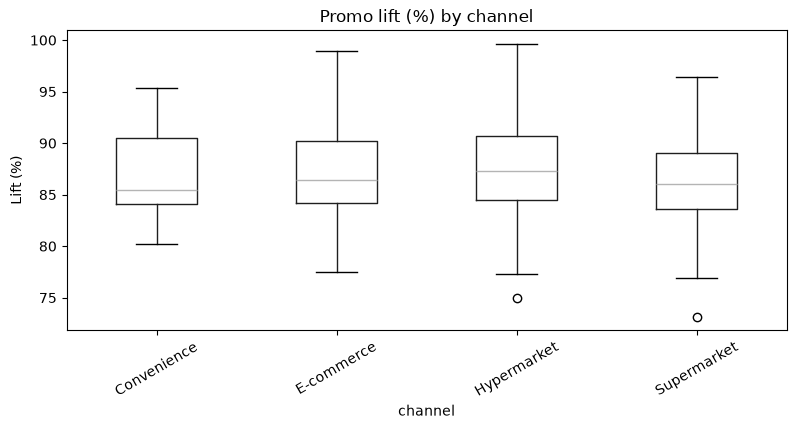

In [9]:
attrs = dfa.drop_duplicates("series_id").set_index("series_id")[["channel", "country", "category"]]
seg = pd.read_csv("../data/abc_xyz_segments.csv").set_index("series_id")[["abc_class", "xyz_rel"]]
lifts = lifts.join(attrs).join(seg)

def compare_groups(col):
    tbl = lifts.groupby(col)["lift_pct"].agg(n="count", mean="mean", std="std")
    tbl["ci95"] = 1.96 * tbl["std"] / np.sqrt(tbl["n"])
    print(f"\n=== Lift (%) by {col} ===")
    print(tbl[["n", "mean", "ci95"]].round(2).to_string())

    groups = [grp["lift_pct"].values for _, grp in lifts.groupby(col)]
    F, p = st.f_oneway(*groups)
    H, pk = st.kruskal(*groups)
    L, pl = st.levene(*groups)
    grand = lifts["lift_pct"].mean()
    eta2 = (tbl["n"] * (tbl["mean"] - grand) ** 2).sum() / ((lifts["lift_pct"] - grand) ** 2).sum()
    print(f"ANOVA: F = {F:.2f}, p = {p:.3g} | Kruskal-Wallis p = {pk:.3g} | Levene p = {pl:.3g}")
    print(f"Eta-squared = {eta2:.3f}  (share of lift variation explained by {col})")

    lifts.boxplot(column="lift_pct", by=col, grid=False)
    plt.title(f"Promo lift (%) by {col}")
    plt.suptitle("")
    plt.ylabel("Lift (%)")
    plt.xticks(rotation=30)
    plt.show()
    return p

p_channel = compare_groups("channel")

In [10]:
# Pairwise comparisons: only meaningful if the channel ANOVA above is significant.
print(pairwise_tukeyhsd(lifts["lift_pct"], lifts["channel"]).summary())

     Multiple Comparison of Means - Tukey HSD, FWER=0.05     
   group1      group2   meandiff p-adj   lower  upper  reject
-------------------------------------------------------------
Convenience  E-commerce   0.7248 0.9164 -2.1636 3.6132  False
Convenience Hypermarket   0.9093  0.831 -1.8542 3.6729  False
Convenience Supermarket  -0.2234 0.9972 -3.1197 2.6729  False
 E-commerce Hypermarket   0.1845 0.9881 -1.2807 1.6496  False
 E-commerce Supermarket  -0.9482 0.4769 -2.6505 0.7541  False
Hypermarket Supermarket  -1.1327 0.1997 -2.6133 0.3479  False
-------------------------------------------------------------


### 6.1 The same test by category, country and ABC class


=== Lift (%) by category ===
                 n   mean  ci95
category                       
Beverages      112 86.950 0.870
Dairy           54 87.340 1.220
Home Care       50 88.070 1.200
Personal Care   70 87.720 1.030
Snacks         117 86.690 0.840
ANOVA: F = 1.13, p = 0.34 | Kruskal-Wallis p = 0.199 | Levene p = 0.965
Eta-squared = 0.011  (share of lift variation explained by category)


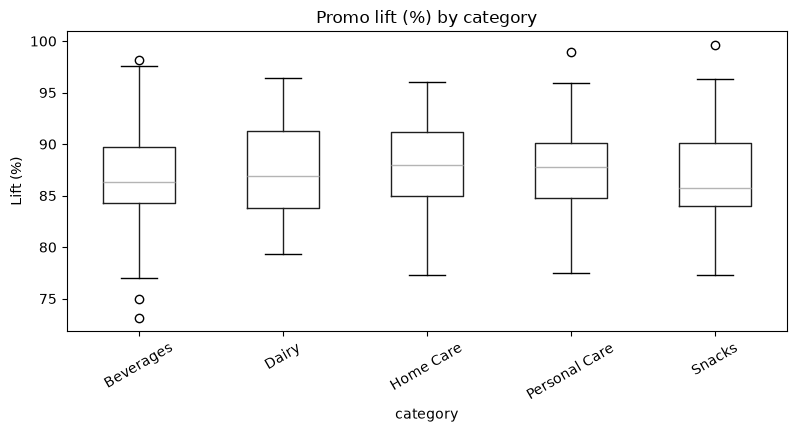


=== Lift (%) by country ===
               n   mean  ci95
country                      
Austria       30 87.750 1.730
France        33 87.550 1.610
Germany       65 87.570 1.250
Italy        127 87.040 0.750
Netherlands   20 86.640 1.850
Poland        34 87.760 1.520
Spain         94 86.780 0.910
ANOVA: F = 0.47, p = 0.83 | Kruskal-Wallis p = 0.718 | Levene p = 0.722
Eta-squared = 0.007  (share of lift variation explained by country)


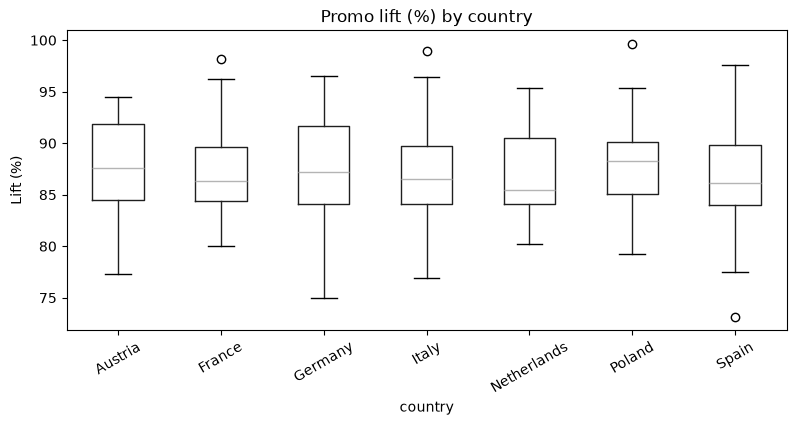


=== Lift (%) by abc_class ===
             n   mean  ci95
abc_class                  
A          177 87.460 0.690
B          135 87.130 0.810
C           91 86.790 0.810
ANOVA: F = 0.68, p = 0.509 | Kruskal-Wallis p = 0.621 | Levene p = 0.0661
Eta-squared = 0.003  (share of lift variation explained by abc_class)


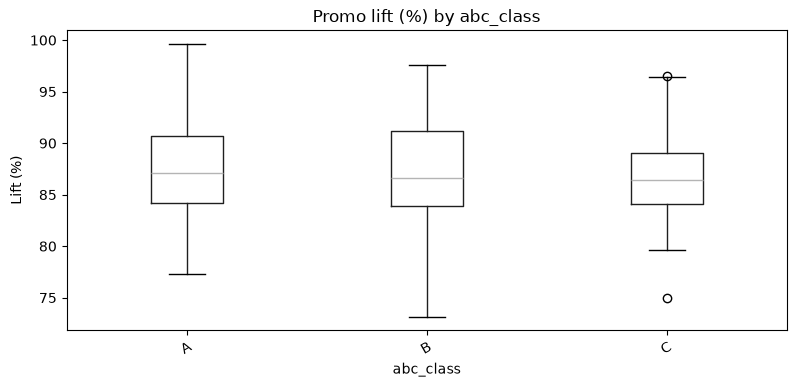

In [11]:
for col in ["category", "country", "abc_class"]:
    compare_groups(col)

In [15]:
promoted = dfa.groupby("series_id")["promo_flag"].max().rename("ever_promoted")
chk = promoted.to_frame().join(attrs)
for col in ["category", "channel", "country"]:
    print(f"\nShare of series ever promoted (%) by {col}:")
    print((chk.groupby(col)["ever_promoted"].mean() * 100).round(1).to_string())


Share of series ever promoted (%) by category:
category
Beverages       46.100
Dairy           30.200
Home Care       30.900
Personal Care   38.500
Snacks          49.000

Share of series ever promoted (%) by channel:
channel
Convenience   44.400
E-commerce    40.400
Hypermarket   40.000
Supermarket   39.200

Share of series ever promoted (%) by country:
country
Austria       37.500
France        41.200
Germany       40.600
Italy         39.700
Netherlands   44.400
Poland        42.500
Spain         39.200


## 7. Lift by discount depth
Promotions come at 10%, 15%, 20% and 30% off. For each series we compare its units at each discount level with its own non-promo baseline, then average across series. Because the same series can appear at several depths, we use the **Friedman test** (a repeated-measures test) to ask whether depth matters.

              series  mean_lift_%  ci95
discount_pct                           
0.100            403       69.600 0.700
0.150            403       79.800 0.700
0.200            403       90.100 0.800
0.300            403      110.200 0.900

Friedman test across depths (403 series with all depths): chi2 = 1009.6, p = 1.51e-218


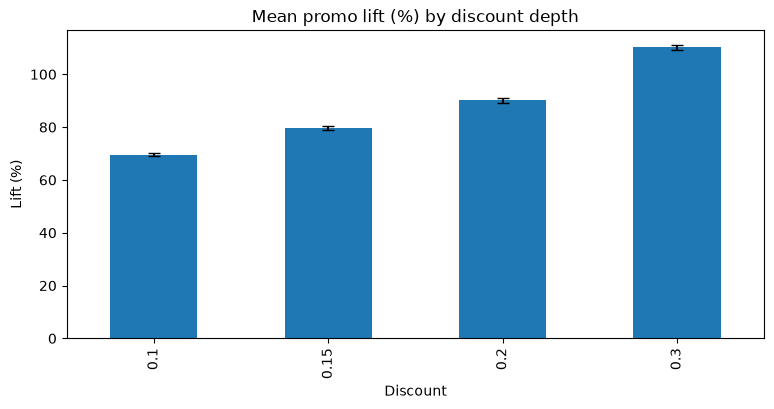

In [12]:
promo_rows = dfa[dfa["promo_flag"] == 1]
by_depth = promo_rows.groupby(["series_id", "discount_pct"])["units_adj"].mean().unstack()
depth_lift = by_depth.div(lifts["units_adj_0"], axis=0) - 1
depth_lift = depth_lift.dropna(how="all") * 100

summary = pd.DataFrame({
    "series": depth_lift.count(),
    "mean_lift_%": depth_lift.mean(),
    "ci95": 1.96 * depth_lift.std() / np.sqrt(depth_lift.count()),
})
print(summary.round(1).to_string())

complete = depth_lift.dropna()
chi, pf = st.friedmanchisquare(*[complete[c] for c in complete.columns])
print(f"\nFriedman test across depths ({len(complete)} series with all depths): chi2 = {chi:.1f}, p = {pf:.3g}")

summary["mean_lift_%"].plot(kind="bar", yerr=summary["ci95"], capsize=4,
                            title="Mean promo lift (%) by discount depth")
plt.xlabel("Discount")
plt.ylabel("Lift (%)")
plt.show()

## 8. Is a promotion profitable?
Lift in units is not the same as lift in profit: a deep discount cuts the margin on every unit. We compare **adjusted gross profit per day** (net sales minus purchase cost) on promo vs non-promo days, per series, and by discount depth. A negative profit lift means the promotion sold more but earned less.

Mean profit lift: -2.8%  (units lift 87.2%)
t-test vs 0: t = -13.6, p = 6.49e-35
Series where promotion REDUCES profit: 75.4%

Mean profit lift (%) and share of series losing profit, by discount depth:
              mean_profit_lift_%  share_losing_%
discount_pct                                    
0.100                     27.300           0.000
0.150                     12.300           4.500
0.200                     -4.700          72.700
0.300                    -47.800         100.000


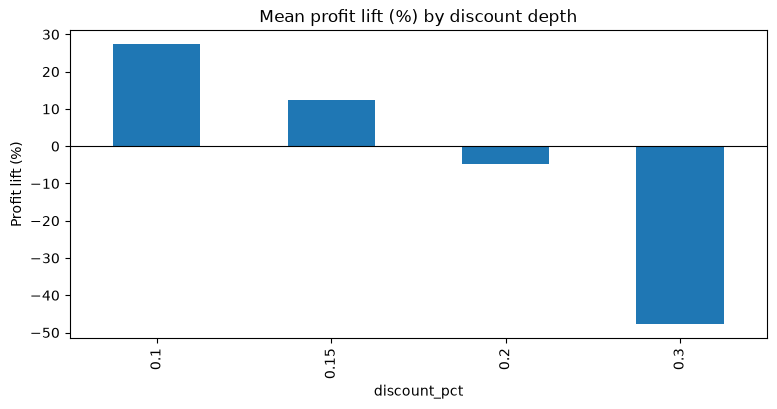

In [13]:
lifts["profit_lift_pct"] = (lifts["profit_adj_1"] / lifts["profit_adj_0"] - 1) * 100

pl = lifts["profit_lift_pct"]
t, p = st.ttest_1samp(pl, 0)
print(f"Mean profit lift: {pl.mean():.1f}%  (units lift {lifts['lift_pct'].mean():.1f}%)")
print(f"t-test vs 0: t = {t:.1f}, p = {p:.2e}")
print(f"Series where promotion REDUCES profit: {(pl < 0).mean()*100:.1f}%")

# By discount depth
profit_by_depth = promo_rows.groupby(["series_id", "discount_pct"])["profit_adj"].mean().unstack()
profit_depth_lift = (profit_by_depth.div(lifts["profit_adj_0"], axis=0) - 1) * 100
print("\nMean profit lift (%) and share of series losing profit, by discount depth:")
out = pd.DataFrame({
    "mean_profit_lift_%": profit_depth_lift.mean(),
    "share_losing_%": (profit_depth_lift < 0).mean() * 100,
})
print(out.round(1).to_string())

out["mean_profit_lift_%"].plot(kind="bar", title="Mean profit lift (%) by discount depth")
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("Profit lift (%)")
plt.show()

## 9. Save series-level results

In [14]:
cols = ["lift_raw", "lift_adj", "lift_pct", "profit_lift_pct", "n_0", "n_1",
        "channel", "country", "category", "abc_class", "xyz_rel"]
lifts[cols].reset_index().to_csv("../data/promo_lift_by_series.csv", index=False)
print("Saved", lifts[cols].shape, "-> data/promo_lift_by_series.csv")

Saved (403, 11) -> data/promo_lift_by_series.csv


## 10. Summary of findings

**Which series are promoted**
- Only 403 of 1,005 series (40%) ever run promotions; in those series about 20% of days are promo days. All lift results apply to these 403 series.

**Confounding check**
- Promo days are spread evenly across months (7.4-8.6% of rows) and weekdays (7.9-8.1%), so timing does not inflate lift: raw lift 86.6% vs seasonally adjusted 87.2%.
- Promo share differs by category (Snacks 9.8%, Beverages 9.2%, Personal Care 7.7%, Home Care 6.2%, Dairy 6.0%).

**Overall lift**
- Mean adjusted lift is 87.2% (95% CI 86.8%-87.6%). All 403 series show positive lift. Cohen's d = 1.78 (very large). The paired t-test (t = 35.8) and Wilcoxon test both give p < 1e-60; the one-sample t-test p-value underflows to 0 (p < 1e-300).

**Differences between groups (one-way ANOVA)**
- Channel: F = 1.44, p = 0.23, eta-squared = 0.011; Tukey HSD finds no significant pair. Category: p = 0.34 (eta-squared 0.011); country: p = 0.83 (0.007); ABC class: p = 0.51 (0.003).
- Lift is about 87% in every group, so promotion response does not vary by channel, category, country or value class. Convenience has only 20 series, so that comparison has lower power.

**Discount depth**
- Mean lift: 10% off 69.6%, 15% 79.8%, 20% 90.1%, 30% 110.2% (Friedman p < 1e-200). Lift rises about 10 points per extra 5 points of discount, approximately linearly.

**Profitability**
- Despite +87.2% units, mean gross profit lift is -2.8% and 75.4% of series lose profit.
- By depth: 10% off +27.3% profit (0% of series lose), 15% +12.3% (4.5%), 20% -4.7% (72.7%), 30% -47.8% (100%). Breakeven is roughly 18-19% discount (linear interpolation across four depths).

**Implications for Phases 4-6**
- `promo_flag` and `discount_pct` are essential features; channel-specific promo effects are not needed.
- A discount cap near 15% protects profit; 30% promotions lose money in every promoted series.
- Limits: observational and very uniform (likely simulated) data; gross profit only, with no post-promo dip, cannibalisation or promo funding costs; stock-out days excluded.